<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Select the region of interest (ROI) of this dataset and save it as `rois/<dataset>/data.zarr` + `metadata.csv`.
> - **Manuscript panels:** Fig. 1A (dataset collection); input to all downstream analyses
> - **Inputs:** Raw vendor output in `rois/raw/`
> - **Outputs:** `rois/<dataset>/data.zarr`, `metadata.csv`
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# 1. Aim of the notebook

In this notebook we will select specific regions of interest to apply troutpy on, with the aim of characterizing the nature of transcripts outside segmented regions

# Part 1 (spatialdata env)
## Import packages

In [ ]:
import spatialdata_io
import spatialdata as sd
#import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys



    
from troutpy import pl
from troutpy import tl
from troutpy import pp

from troutpy_reproducibility.roi_processing import *


/home/icb/sergio.salas/miniconda3/envs/sd_convert/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


## Read main path to .zarr file

In [ ]:
inpath = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/raw_datasets/xenium_multimodal"
import spatialdata as sd
import spatialdata_io
from spatialdata.models import Image2DModel
import dask_image.imread
import os

# 1. Load the base Xenium data (transcripts, boundaries, etc.)
# Set morphology_focus=None to skip the problematic auto-loading of images
sdata = spatialdata_io.xenium(inpath)


In [ ]:
sdata.write('/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/raw_datasets/multimodal.zarr',overwrite=True)

# Part2 (troutpy kernel)

In [3]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys



    
from troutpy import pl
from troutpy import tl
from troutpy import pp

from troutpy_reproducibility.roi_processing import *


In [ ]:
#sdata=sd.read('/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/raw_datasets/multimodal.zarr',overwrite=True)

We decide to keep the data in a unified scale (um), which then can be transformated to 'global' coordinates using the according transformation. This global transformation is specially useful for matching the sales of transcripts with ie images

In [12]:
bb_xmin= 15000
bb_xmax = 30000
bb_ymin = 5000
bb_ymax = 15000

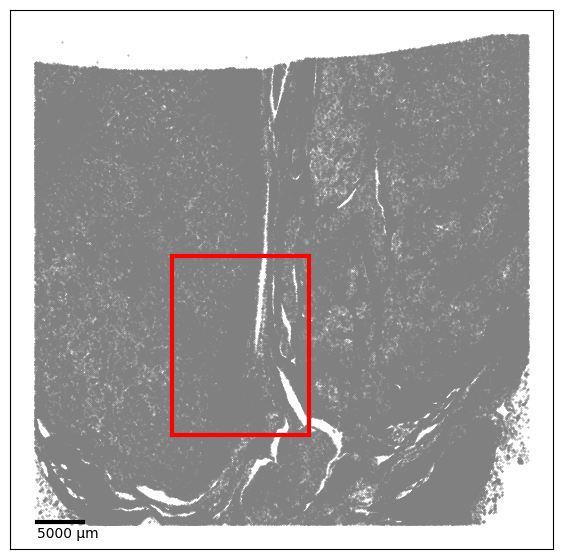

In [13]:
plot_spatial_with_box_and_scale(
    spatial_coords=sdata["table"].obsm["spatial"], bb_xmin=bb_xmin, bb_xmax=bb_xmax, bb_ymin=bb_ymin, bb_ymax=bb_ymax
)

Next, we select the ROI of interest

In [14]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],
    target_coordinate_system="global",
)

# Save metadata
metadata = generate_metadata(
    sdata=cropped_sdata,
    sample_id="hs_rcc_multiomics",
    species="Homo sapiens",
    technology="Xenium",
    segmentation_method="multimodal",
    roi_name="rcc",
    tissue="Kidney",
    disease="Renal cell carcinoma",
)

rechunk_sdata(cropped_sdata)

Processing image: morphology_focus
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing label: nucleus_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing label: cell_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...


In [18]:
import copy

import numpy as np
import pandas as pd
import spatialdata as sd
import xarray as xr
from spatialdata.models import Image2DModel, Labels2DModel, TableModel


def xenium_converter(sdata, copy=False, unassigned_tag="UNASSIGNED"):
    """
    Converts a SpatialData object (sdata) into the Xenium format.

    Parameters
    ----------
    sdata : spatialdata.SpatialData
        A SpatialData object with attributes such as Images, Points, and Tables, conforming to the structure detailed in the SpatialData documentation.

    Returns
    -------
    sdata : spatialdata.SpatialData
        The converted SpatialData object with the modifications applied.
    """
    # ----- 1. Modify the Points/transcripts DataFrame -----
    try:
        transcripts = sdata["transcripts"].compute().reset_index(drop=True)
    except (KeyError, AttributeError) as e:
        raise ValueError("SpatialData must contain Points['transcripts'] as a DataFrame.") from e

    # a. Rename 'feature_name' to 'Gene' and convert to categorical
    if "feature_name" in transcripts.columns:
        transcripts = transcripts.rename(columns={"feature_name": "gene"})
        transcripts["gene"] = transcripts["gene"].astype("category")
    else:
        print("Warning: 'feature_name' column not found in Points['transcripts'].")

    # b. Create new boolean column 'control_probe' based on 'codeword_category'
    if "codeword_category" in transcripts.columns:
        transcripts["control_probe"] = transcripts["codeword_category"].apply(lambda x: False if x == "predesigned_gene" else True)
    else:
        print("Warning: 'codeword_category' column not found in Points['transcripts']. Gene name-based control probe assignment will be used.")
        transcripts["control_probe"] = transcripts["gene"].str.startswith(("Neg", "BLANK"))

    # c. Ensure 'transcript_id' is a string and has unique values.
    if "transcript_id" in transcripts.columns:
        transcripts["transcript_id"] = transcripts["transcript_id"].astype(str)
        if transcripts["transcript_id"].duplicated().any():
            raise ValueError("Duplicate values found in 'transcript_id'. They must be unique.")
    else:
        print("Warning: 'transcript_id' column not found in Points['transcripts'].")

    # d. Convert 'overlaps_nucleus' to boolean.
    if "overlaps_nucleus" in transcripts.columns:
        transcripts["overlaps_nucleus"] = transcripts["overlaps_nucleus"].astype(bool)
    else:
        print("Warning: 'overlaps_nucleus' column not found in Points['transcripts'].")

    # e. Create new 'overlaps_cell' boolean column based on 'cell_id'.
    if "cell_id" in transcripts.columns:
        transcripts["overlaps_cell"] = transcripts["cell_id"].apply(lambda x: False if x == unassigned_tag else True)
    else:
        print("Warning: 'cell_id' column not found in Points['transcripts']. Cannot create 'overlaps_cell'.")

    # Update the transcripts in Points
    sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)

    # ----- 2. Modify the Tables object -----
    try:
        table = sdata["table"]
    except (KeyError, AttributeError) as e:
        raise ValueError("SpatialData must contain Tables['table'] as an AnnData object.") from e

    # Verify that table.obs contains the 'cell_id' column.
    if "cell_id" not in table.obs.columns:
        raise ValueError("Tables['table'].obs must contain a 'cell_id' column.")
    # Ensure the index is unique.
    if table.obs.index.duplicated().any():
        raise ValueError("Tables['table'].obs index contains duplicates. They must be unique.")
    # Create a new layer 'raw' storing a copy of table.X (raw expression data).
    try:
        table.var["gene_id"] = table.var.index
        table.var.index = table.var["gene_names"]
    except KeyError:
        print("Warning: 'gene_names' column not found in Tables['table']. Using default index.")
    if table.X is None:
        raise ValueError("Tables['table'] must have an expression matrix in .X.")
    if not hasattr(table, "layers") or table.layers is None:
        table.layers = {}
    table.layers["raw"] = table.X.copy()

    # ----- 3. Move Images to Stainings -----
    try:
        morph_focus = sdata["morphology_focus"]
    except (KeyError, AttributeError):
        print("Warning: SpatialData does not have Images['morphology_focus'].")
        morph_focus = None

    if morph_focus is not None:
        # Assume morph_focus is a DataTree (or similar dict-like object) with keys for different scales.
        if "scale0" in morph_focus:
            pass
            # default_image = morph_focus["scale0"]
        else:
            print("Warning: 'scale0' not found in Images['morphology_focus']. Using first available scale.")
            # default_image = next(iter(morph_focus.values()))

        # Create or update the Stainings attribute.
        # if not hasattr(sdata, "Stainings") or sdata.images is None:
        #    sdata.images = {}
        # sdata["default"] = default_image

    return sdata if copy else None


def process_image_data(sdata: sd.SpatialData) -> xr.DataArray:
    """Stitch all FOV image tiles stored in ``sdata.images`` into a single global image.

    Tile positions are read from each tile's ``"global"`` affine transform matrix.
    Overlapping regions are overwritten (last tile wins).

    Parameters
    ----------
    sdata : spatialdata.SpatialData
        SpatialData object whose ``images`` attribute contains per-FOV image tiles as
        3-channel (c, y, x) arrays with an affine ``"global"`` transform.

    Returns
    -------
    xarray.DataArray
        Stitched image of shape ``(3, canvas_height, canvas_width)`` with dimensions
        ``("c", "y", "x")``.
    """
    fov_keys = list(sdata.images.data.keys())
    sample_raw = sdata.images.data[fov_keys[0]].data
    sample = sample_raw.compute() if hasattr(sample_raw, "compute") else sample_raw
    h, w = sample.shape[1:]
    x_offs, y_offs = {}, {}
    for key in fov_keys:
        M = sdata.images.data[key].transform["global"].matrix
        x_offs[key], y_offs[key] = M[0, 2], M[1, 2]
    x_min, y_min = min(x_offs.values()), min(y_offs.values())
    x_max = max(x_offs[key] + w for key in fov_keys)
    y_max = max(y_offs[key] + h for key in fov_keys)
    canvas_w = int(np.ceil(x_max - x_min))
    canvas_h = int(np.ceil(y_max - y_min))
    canvas = np.zeros((3, canvas_h, canvas_w), dtype=np.uint8)
    for key in fov_keys:
        tile_raw = sdata.images.data[key].data
        tile = tile_raw.compute() if hasattr(tile_raw, "compute") else tile_raw
        x0 = int(round(x_offs[key] - x_min))
        y0 = int(round(y_offs[key] - y_min))
        canvas[:, y0 : y0 + h, x0 : x0 + w] = tile
    return xr.DataArray(canvas, dims=("c", "y", "x"))


def process_label_data(sdata: sd.SpatialData) -> (xr.DataArray, dict):
    """Stitch per-FOV label tiles into a global label image, assigning globally unique cell IDs.

    Each tile's cell labels are re-mapped to a new contiguous integer range so that
    no two FOVs share a cell ID. The mapping from ``(fov, original_id)`` to the new
    global ID is returned for downstream remapping of transcript and table data.

    Parameters
    ----------
    sdata : spatialdata.SpatialData
        SpatialData object whose ``labels`` attribute contains per-FOV label tiles with
        an affine ``"global"`` transform. FOV indices are inferred from the tile key
        prefix (e.g. ``"1_labels"`` → FOV 1).

    Returns
    -------
    global_labels : xarray.DataArray
        Stitched integer label image of shape ``(canvas_height, canvas_width)``
        with dimensions ``("y", "x")``.
    id_map : dict
        Mapping ``{(fov, original_cell_id): new_global_cell_id}`` for all non-background
        cells across all FOVs.
    """
    fov_keys = list(sdata.labels.data.keys())
    sample_raw = sdata.labels.data[fov_keys[0]].data
    sample = sample_raw.compute() if hasattr(sample_raw, "compute") else sample_raw
    h, w = sample.shape[:2]
    x_offs, y_offs = {}, {}
    for key in fov_keys:
        M = sdata.labels.data[key].transform["global"].matrix
        x_offs[key], y_offs[key] = M[0, 2], M[1, 2]
    x_min, y_min = min(x_offs.values()), min(y_offs.values())
    x_max = max(x_offs[key] + w for key in fov_keys)
    y_max = max(y_offs[key] + h for key in fov_keys)
    canvas_w = int(np.ceil(x_max - x_min))
    canvas_h = int(np.ceil(y_max - y_min))
    global_lbl = np.zeros((canvas_h, canvas_w), dtype=sample.dtype)

    next_id = 1
    id_map = {}
    for key in fov_keys:
        # derive numeric fov from key, e.g. '1_points' -> 1
        fov = int(str(key).split("_", 1)[0])
        tile_raw = sdata.labels.data[key].data
        tile = tile_raw.compute() if hasattr(tile_raw, "compute") else tile_raw
        unique_ids = np.unique(tile[tile > 0])
        # map using numeric fov
        tile_map = {(fov, orig): next_id + i for i, orig in enumerate(unique_ids)}
        id_map.update(tile_map)
        next_id += len(unique_ids)
        rel = np.zeros_like(tile)
        for (_fv, orig), new in tile_map.items():
            rel[tile == orig] = new
        x0 = int(round(x_offs[key] - x_min))
        y0 = int(round(y_offs[key] - y_min))
        sub = global_lbl[y0 : y0 + h, x0 : x0 + w]
        mask = (sub == 0) & (rel > 0)
        sub[mask] = rel[mask]
        global_lbl[y0 : y0 + h, x0 : x0 + w] = sub
    return xr.DataArray(global_lbl, dims=("y", "x")), id_map


def process_transcript_data(sdata: sd.SpatialData) -> pd.DataFrame:
    """Concatenate per-FOV transcript tiles and prepare global coordinate columns.

    Each tile's local ``x``/``y`` columns are preserved as ``local_x``/``local_y``,
    global pixel coordinates are promoted to ``x``/``y``, the ``target`` column is
    renamed to ``gene``, and boolean ``overlaps_cell`` / ``overlaps_nuclei`` columns
    are derived.

    Parameters
    ----------
    sdata : spatialdata.SpatialData
        SpatialData object whose ``points`` attribute contains per-FOV transcript tiles.
        Each tile must have ``x_global_px``, ``y_global_px``, ``target``, ``cell_ID``,
        and ``CellComp`` columns.

    Returns
    -------
    tx : pandas.DataFrame
        Concatenated transcript DataFrame with columns ``"x"``, ``"y"``, ``"gene"``,
        ``"fov"``, ``"transcript_id"``, ``"overlaps_cell"``, ``"overlaps_nuclei"``,
        and ``"control_probe"``.
    """
    dfs = []
    for key in sdata.points.data.keys():
        fov = int(str(key).split("_", 1)[0])
        elem = sdata.points.data[key]
        raw = elem.data if hasattr(elem, "data") else elem
        df = raw.compute() if hasattr(raw, "compute") else raw
        df["fov"] = fov
        dfs.append(df)
    tx = pd.concat(dfs, ignore_index=True)
    tx["local_x"] = tx["x"]
    tx["local_y"] = tx["y"]
    tx.drop(columns=["x", "y"], inplace=True)
    tx.rename(columns={"x_global_px": "x", "y_global_px": "y", "target": "gene"}, inplace=True)
    tx["transcript_id"] = np.arange(len(tx))
    tx["overlaps_cell"] = tx["cell_ID"] != 0
    tx["overlaps_nuclei"] = tx["CellComp"] == "Nuclear"
    tx["overlaps_nuclei"].fillna(False, inplace=True)
    tx["control_probe"] = tx["gene"].str.startswith(("NegPr", "System"))
    if "global" in sdata["table"].obsm:
        sdata["table"].obsm["spatial"] = sdata["table"].obsm["global"].copy()
    return tx


def cosmx_converter(sdata: sd.SpatialData, copy_data: bool = False) -> sd.SpatialData:
    """Convert a CosMx multi-FOV SpatialData object into a unified single-coordinate-system object.

    Stitches image and label tiles, concatenates transcript tiles, remaps all
    per-FOV cell IDs to globally unique integers, and repacks the result into a
    standard SpatialData structure with a single image, label, points, shapes, and
    table layer.

    Parameters
    ----------
    sdata : spatialdata.SpatialData
        Raw CosMx SpatialData object with per-FOV images, labels, points, and a
        ``"table"`` AnnData. The table's ``obs`` must contain ``"fov"`` and
        ``"cell_ID"`` columns for cell ID remapping.
    copy_data : bool, optional
        If ``True``, operate on a deep copy of ``sdata`` and return it.
        Otherwise modify in place and return ``None``. Defaults to ``False``.

    Returns
    -------
    spatialdata.SpatialData or None
        Converted SpatialData object if ``copy_data=True``; otherwise ``None``.

    Raises
    ------
    ValueError
        If ``sdata.table.obs`` does not contain a ``"fov"`` column required for
        cell ID remapping.
    """
    sdata_out = copy.deepcopy(sdata) if copy_data else sdata
    # 1) stitch
    img_da = process_image_data(sdata_out)
    lbl_da, id_map = process_label_data(sdata_out)
    # 2) transcripts
    tx_df = process_transcript_data(sdata_out)
    # 3) remap transcripts
    tx_df["cell_ID"] = tx_df.apply(lambda r: id_map.get((r["fov"], r["cell_ID"]), 0), axis=1).astype(int)
    # 4) remap table
    if "cell_ID" in sdata_out.table.obs:
        if "fov" not in sdata_out.table.obs.columns:
            raise ValueError("table.obs must contain numeric 'fov' column to remap cell_IDs.")
        sdata_out.table.obs["cell_ID"] = sdata_out.table.obs.apply(lambda r: id_map.get((int(r["fov"]), r["cell_ID"]), 0), axis=1).astype(int)
    # 5) shift coords
    min_x, min_y = tx_df["x"].min(), tx_df["y"].min()
    tx_df["x"] -= min_x
    tx_df["y"] -= min_y
    if "spatial" in sdata_out.table.obsm:
        sdata_out.table.obsm["spatial"][:, 0] -= min_x
        sdata_out.table.obsm["spatial"][:, 1] -= min_y
    # 6) pack
    sdata_out.images = {
        "morphology_focus": Image2DModel.parse(data=img_da, scale_factors=(2, 2), c_coords=sdata_out[list(sdata_out.images.keys())[0]].c.data)
    }
    sdata_out.labels = {"labels": Labels2DModel.parse(data=lbl_da, scale_factors=(2, 2))}
    sdata_out.points = {"transcripts": sd.models.PointsModel.parse(tx_df)}
    # 7) shapes + metadata
    sdata_out["shapes"] = sd.to_polygons(sdata_out.labels["labels"])
    sdata_out["shapes"].index = sdata_out["shapes"].index.astype(int)

    # format data

    sdata_out["table"].obs["region"] = "shapes"
    original_table = sdata_out["table"].copy()
    try:
        del original_table.uns["spatialdata_attrs"]
    except KeyError:
        print("Key 'spatialdata_attrs' not found in original_table.uns; skipping deletion.")

    # re-parse that AnnData into a SpatialData table layer
    sdata_out["table"] = TableModel.parse(
        original_table,
        region="shapes",  # or whatever region_key you want
        region_key="region",
        instance_key="cell_ID",
    )
    return sdata_out if copy_data else None


In [19]:
# troutpy converter to xenium
xenium_converter(cropped_sdata, unassigned_tag="UNASSIGNED")

In [21]:
output_path = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_rcc"



In [22]:
# Define output paths
zarr_path = os.path.join(output_path, "data.zarr")
metadata_path = os.path.join(output_path, "metadata.csv")

cropped_sdata.write(zarr_path, overwrite=True)
metadata.to_csv(metadata_path, index=False)